# Powerlifting Data: Comprehensive Exploratory Data Analysis (EDA)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("white")
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['figure.figsize'] = (10, 6)

df = pd.read_csv('../data/processed/clean_data.csv', low_memory=False)
sbd_df = df[df['event'] == 'SBD'].copy()


## 1. Event Type Popularity


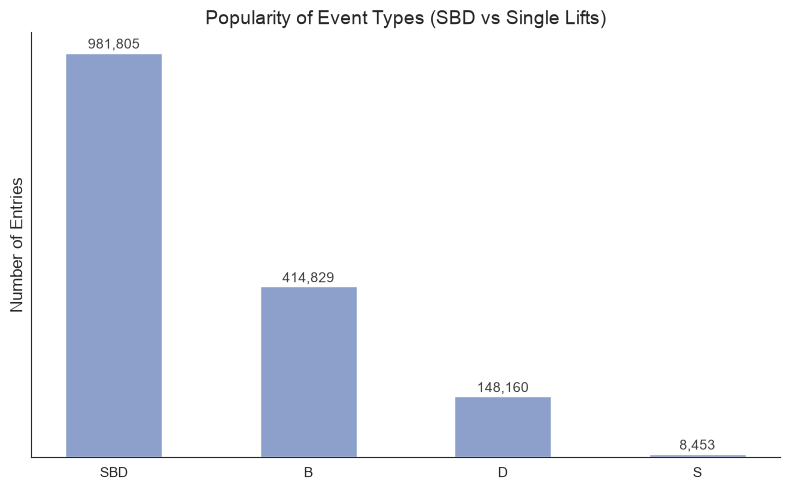

In [2]:
fig, ax = plt.subplots(figsize=(8, 5))
event_counts = df['event'].value_counts()
ax.bar(event_counts.index, event_counts.values, color='#8da0cb', width=0.5)
ax.set_title("Popularity of Event Types (SBD vs Single Lifts)")
ax.set_ylabel("Number of Entries")
for i, v in enumerate(event_counts.values):
    ax.text(i, v + 10000, f"{v:,}", ha='center', color='#404040')
ax.set_yticks([])
plt.tight_layout()
plt.show()


## 2. Age Distribution


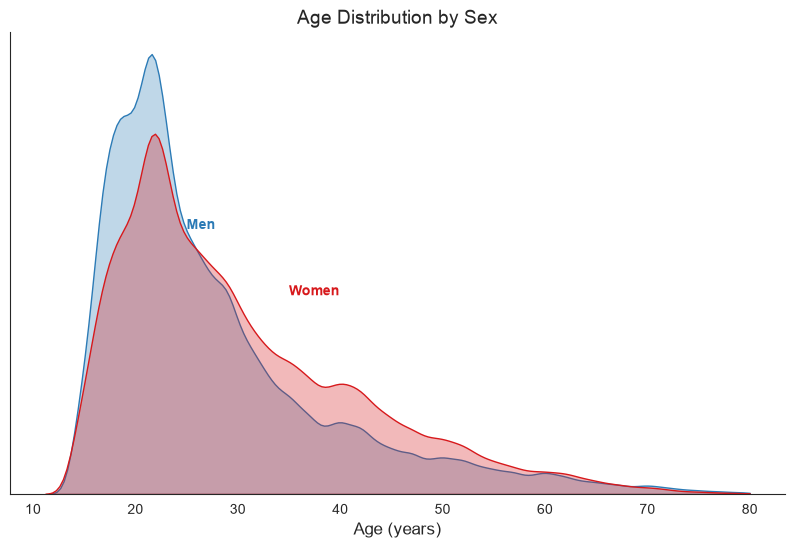

In [3]:
fig, ax = plt.subplots()
for sex, color in [('M', '#2c7bb6'), ('F', '#d7191c')]:
    sns.kdeplot(sbd_df[sbd_df['sex'] == sex]['age'], fill=True, alpha=0.3, color=color, ax=ax, clip=(10, 80))
ax.text(25, 0.04, 'Men', color='#2c7bb6', weight='bold')
ax.text(35, 0.03, 'Women', color='#d7191c', weight='bold')
ax.set_title("Age Distribution by Sex")
ax.set_xlabel("Age (years)")
ax.set_yticks([])
ax.set_ylabel("")
plt.show()


## 3. Total Lifted Distribution


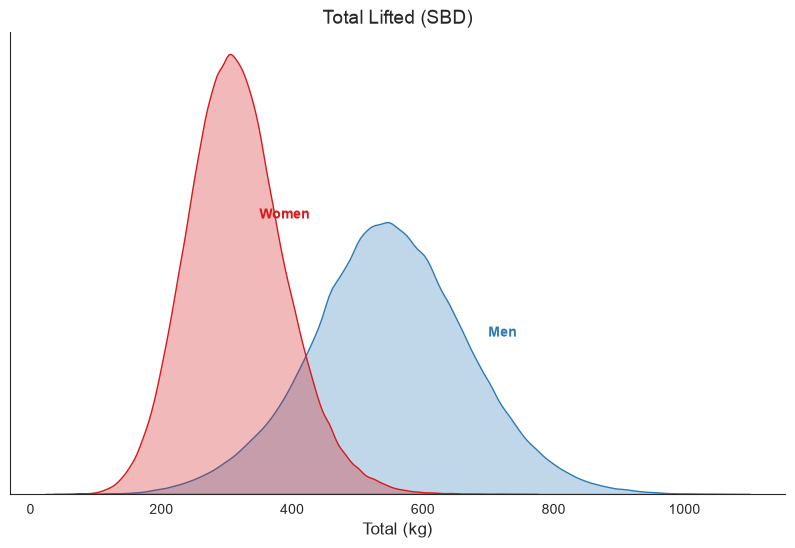

In [4]:
fig, ax = plt.subplots()
for sex, color in [('M', '#2c7bb6'), ('F', '#d7191c')]:
    sns.kdeplot(sbd_df[sbd_df['sex'] == sex]['total'], fill=True, alpha=0.3, color=color, ax=ax, clip=(0, 1100))
ax.text(700, 0.002, 'Men', color='#2c7bb6', weight='bold')
ax.text(350, 0.0035, 'Women', color='#d7191c', weight='bold')
ax.set_title("Total Lifted (SBD)")
ax.set_xlabel("Total (kg)")
ax.set_yticks([])
ax.set_ylabel("")
plt.show()


## 4. Individual Lifts (Squat, Bench, Deadlift)


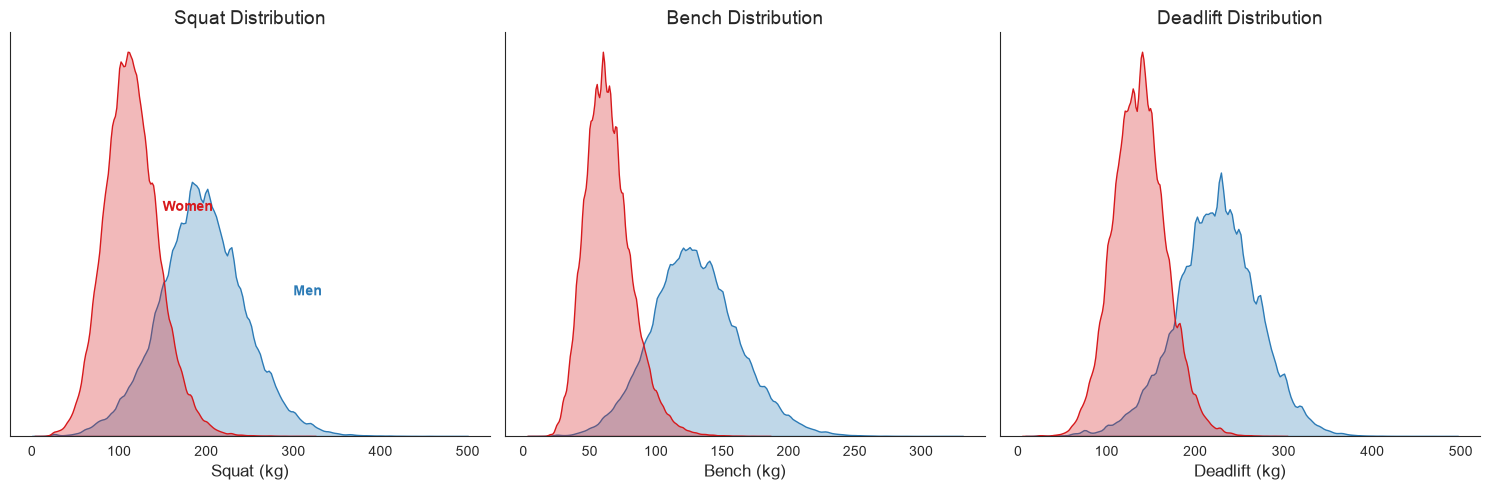

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
lifts = [('squat', 300, 0.005), ('bench', 180, 0.008), ('deadlift', 320, 0.004)]
for ax, (lift, label_x, label_y) in zip(axes, lifts):
    for sex, color in [('M', '#2c7bb6'), ('F', '#d7191c')]:
        sns.kdeplot(sbd_df[sbd_df['sex'] == sex][lift], fill=True, alpha=0.3, color=color, ax=ax)
    ax.set_title(f"{lift.capitalize()} Distribution")
    ax.set_xlabel(f"{lift.capitalize()} (kg)")
    ax.set_yticks([])
    ax.set_ylabel("")
axes[0].text(300, 0.005, 'Men', color='#2c7bb6', weight='bold')
axes[0].text(150, 0.008, 'Women', color='#d7191c', weight='bold')
plt.tight_layout()
plt.show()


## 5. Bodyweight Distribution


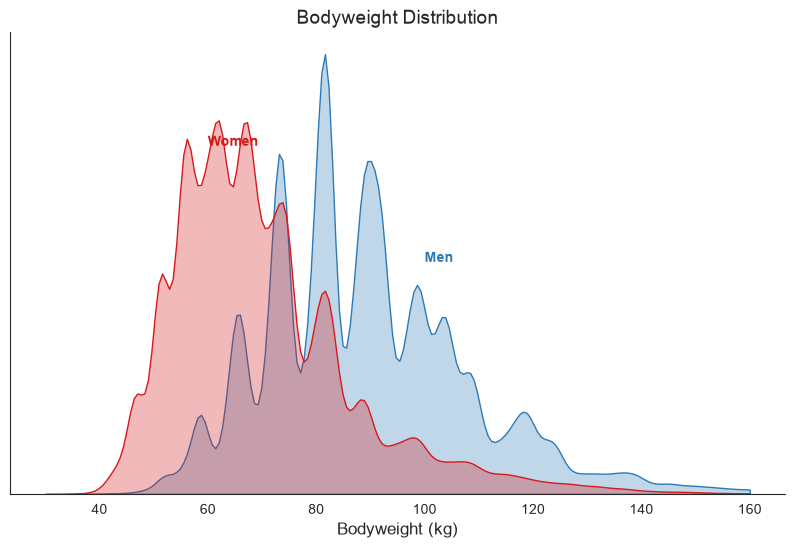

In [6]:
fig, ax = plt.subplots()
for sex, color in [('M', '#2c7bb6'), ('F', '#d7191c')]:
    sns.kdeplot(sbd_df[sbd_df['sex'] == sex]['bodyweight'], fill=True, alpha=0.3, color=color, ax=ax, clip=(30, 160))
ax.text(100, 0.02, 'Men', color='#2c7bb6', weight='bold')
ax.text(60, 0.03, 'Women', color='#d7191c', weight='bold')
ax.set_title("Bodyweight Distribution")
ax.set_xlabel("Bodyweight (kg)")
ax.set_yticks([])
ax.set_ylabel("")
plt.show()


## 6. Relative Strength (DOTS)


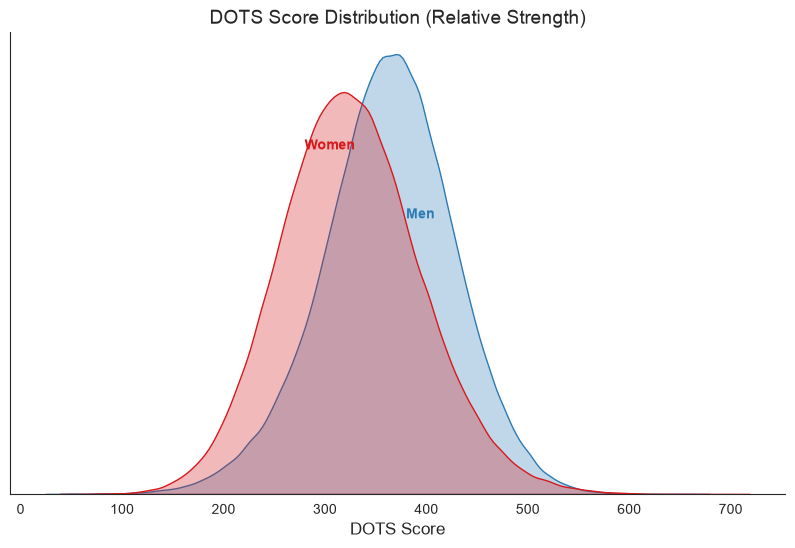

In [7]:
fig, ax = plt.subplots()
for sex, color in [('M', '#2c7bb6'), ('F', '#d7191c')]:
    sns.kdeplot(sbd_df[sbd_df['sex'] == sex]['dots_score'], fill=True, alpha=0.3, color=color, ax=ax)
ax.text(380, 0.004, 'Men', color='#2c7bb6', weight='bold')
ax.text(280, 0.005, 'Women', color='#d7191c', weight='bold')
ax.set_title("DOTS Score Distribution (Relative Strength)")
ax.set_xlabel("DOTS Score")
ax.set_yticks([])
ax.set_ylabel("")
plt.show()


## 7. Weight Class Popularity (Men IPF)


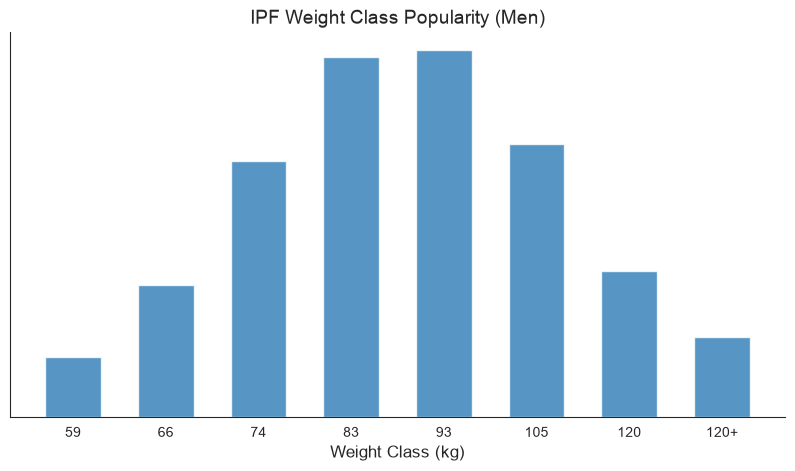

In [8]:
ipf_classes_m = ['59', '66', '74', '83', '93', '105', '120', '120+']
m_ipf = sbd_df[(sbd_df['sex'] == 'M') & (sbd_df['weight_class'].isin(ipf_classes_m))].copy()
m_ipf['weight_class'] = pd.Categorical(m_ipf['weight_class'], categories=ipf_classes_m, ordered=True)

fig, ax = plt.subplots(figsize=(10, 5))
counts = m_ipf['weight_class'].value_counts(sort=False)
ax.bar(counts.index, counts.values, color='#2c7bb6', width=0.6, alpha=0.8)
ax.set_title("IPF Weight Class Popularity (Men)")
ax.set_xlabel("Weight Class (kg)")
ax.set_yticks([])
plt.show()


## 8. Weight Class Popularity (Women IPF)


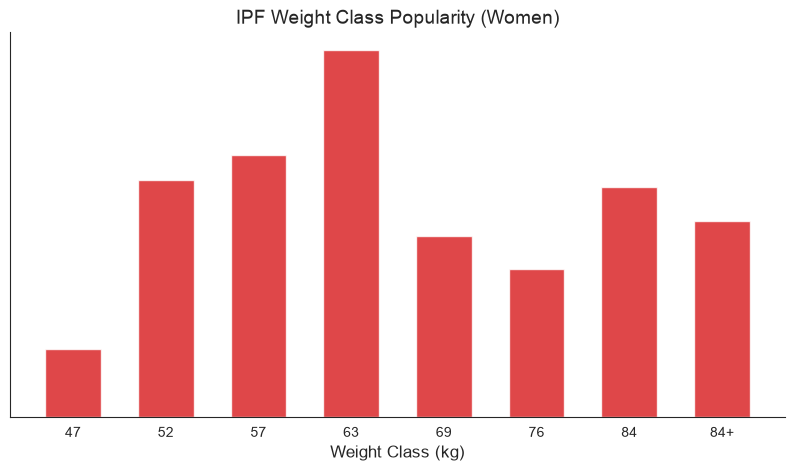

In [9]:
ipf_classes_f = ['47', '52', '57', '63', '69', '76', '84', '84+']
f_ipf = sbd_df[(sbd_df['sex'] == 'F') & (sbd_df['weight_class'].isin(ipf_classes_f))].copy()
f_ipf['weight_class'] = pd.Categorical(f_ipf['weight_class'], categories=ipf_classes_f, ordered=True)

fig, ax = plt.subplots(figsize=(10, 5))
counts = f_ipf['weight_class'].value_counts(sort=False)
ax.bar(counts.index, counts.values, color='#d7191c', width=0.6, alpha=0.8)
ax.set_title("IPF Weight Class Popularity (Women)")
ax.set_xlabel("Weight Class (kg)")
ax.set_yticks([])
plt.show()


## 9. Tested vs Untested DOTS (Men 24-39)


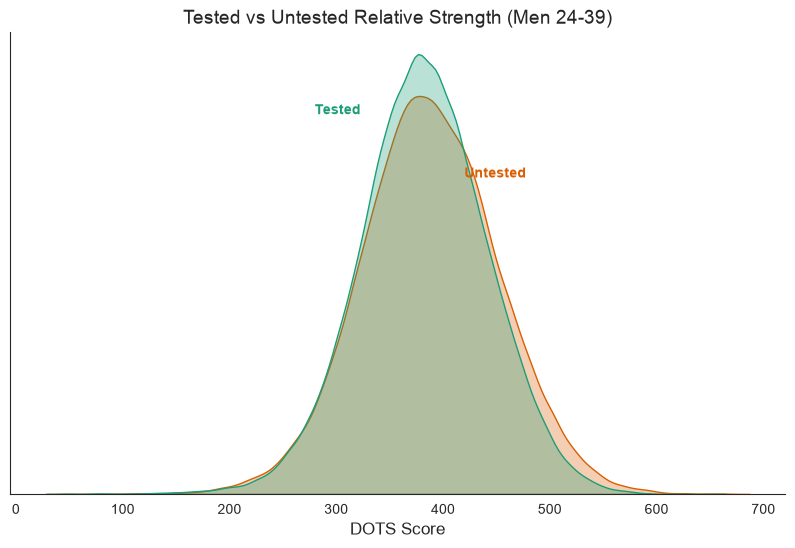

In [10]:
adult_men = sbd_df[(sbd_df['sex'] == 'M') & (sbd_df['age_bracket'].isin(['24-29', '30-39']))]
fig, ax = plt.subplots()
sns.kdeplot(data=adult_men[adult_men['tested_status'] == False], x='dots_score', fill=True, alpha=0.3, color='#d95f02', ax=ax)
sns.kdeplot(data=adult_men[adult_men['tested_status'] == True], x='dots_score', fill=True, alpha=0.3, color='#1b9e77', ax=ax)
ax.text(420, 0.005, 'Untested', color='#d95f02', weight='bold')
ax.text(280, 0.006, 'Tested', color='#1b9e77', weight='bold')
ax.set_title("Tested vs Untested Relative Strength (Men 24-39)")
ax.set_xlabel("DOTS Score")
ax.set_yticks([])
ax.set_ylabel("")
plt.show()


## 10. Age vs Median Relative Strength


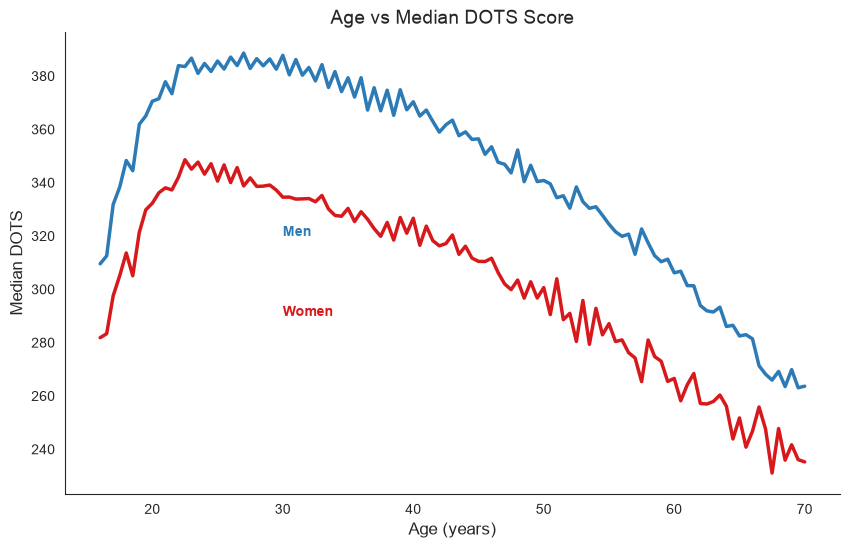

In [11]:
age_stats = sbd_df.groupby(['age', 'sex'])['dots_score'].median().reset_index()
age_stats = age_stats[(age_stats['age'] >= 16) & (age_stats['age'] <= 70)]
fig, ax = plt.subplots()
for sex, color in [('M', '#2c7bb6'), ('F', '#d7191c')]:
    subset = age_stats[age_stats['sex'] == sex]
    ax.plot(subset['age'], subset['dots_score'], color=color, linewidth=2.5)
ax.text(30, 320, "Men", color='#2c7bb6', weight='bold')
ax.text(30, 290, "Women", color='#d7191c', weight='bold')
ax.set_title("Age vs Median DOTS Score")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Median DOTS")
plt.show()


## 11. Bodyweight vs Total Lifted


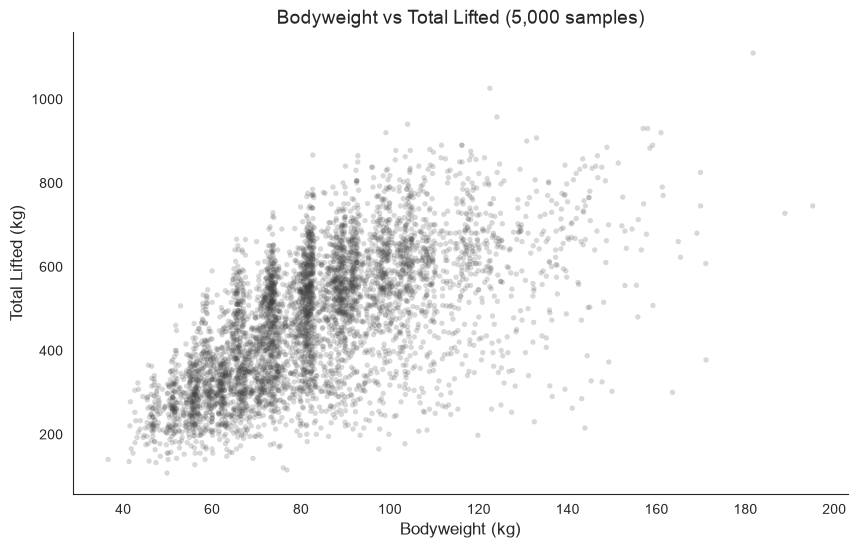

In [12]:
np.random.seed(42)
sample = sbd_df.sample(5000)
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(sample['bodyweight'], sample['total'], alpha=0.2, s=15, color='#404040', edgecolors='none')
ax.set_title("Bodyweight vs Total Lifted (5,000 samples)")
ax.set_xlabel("Bodyweight (kg)")
ax.set_ylabel("Total Lifted (kg)")
plt.show()


## 12. Squat vs Deadlift


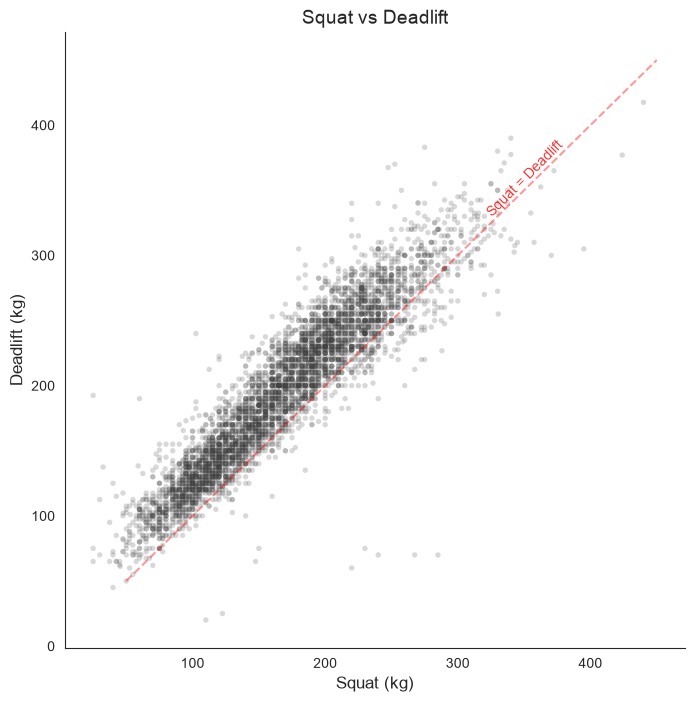

In [13]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(sample['squat'], sample['deadlift'], alpha=0.2, s=15, color='#404040', edgecolors='none')
min_val, max_val = 50, 450
ax.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', alpha=0.4)
ax.text(320, 330, 'Squat = Deadlift', color='red', rotation=45, alpha=0.8)
ax.set_title("Squat vs Deadlift")
ax.set_xlabel("Squat (kg)")
ax.set_ylabel("Deadlift (kg)")
plt.show()


## 13. Bench vs Squat


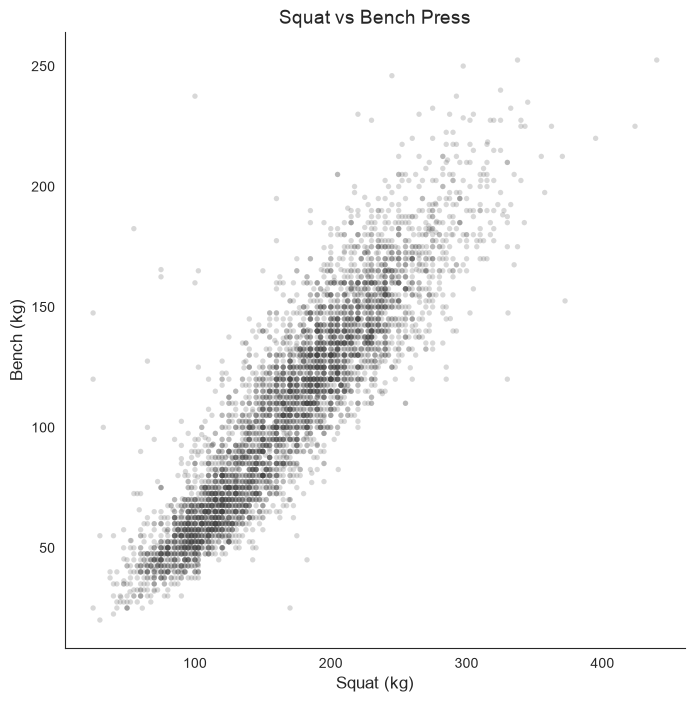

In [14]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(sample['squat'], sample['bench'], alpha=0.2, s=15, color='#404040', edgecolors='none')
ax.set_title("Squat vs Bench Press")
ax.set_xlabel("Squat (kg)")
ax.set_ylabel("Bench (kg)")
plt.show()


## 14. Lift Ratio: Bench / Squat


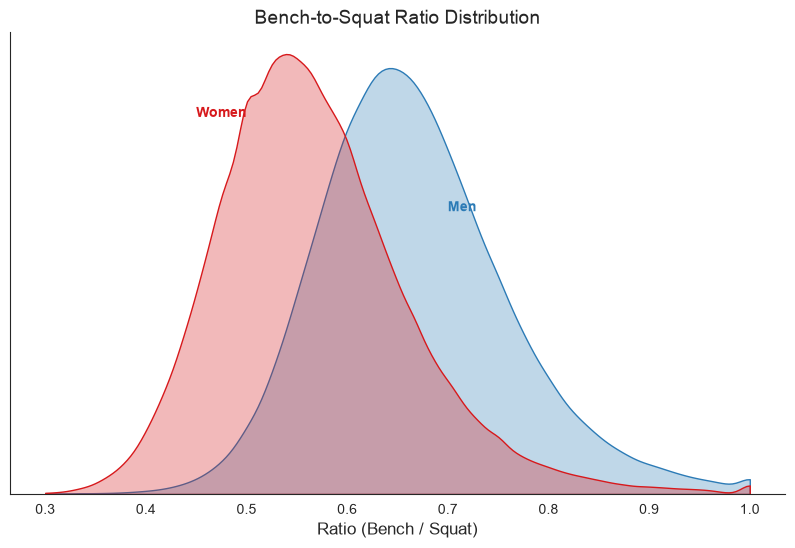

In [15]:
sbd_df['bench_squat_ratio'] = sbd_df['bench'] / sbd_df['squat']
fig, ax = plt.subplots()
for sex, color in [('M', '#2c7bb6'), ('F', '#d7191c')]:
    sns.kdeplot(sbd_df[sbd_df['sex'] == sex]['bench_squat_ratio'], fill=True, alpha=0.3, color=color, ax=ax, clip=(0.3, 1.0))
ax.text(0.7, 3, 'Men', color='#2c7bb6', weight='bold')
ax.text(0.45, 4, 'Women', color='#d7191c', weight='bold')
ax.set_title("Bench-to-Squat Ratio Distribution")
ax.set_xlabel("Ratio (Bench / Squat)")
ax.set_yticks([])
ax.set_ylabel("")
plt.show()


## 15. Lift Ratio: Deadlift / Squat


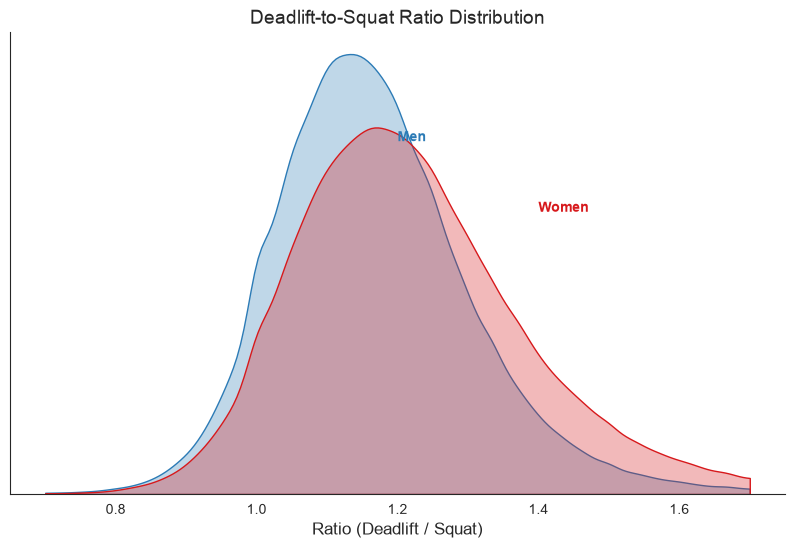

In [16]:
sbd_df['dl_squat_ratio'] = sbd_df['deadlift'] / sbd_df['squat']
fig, ax = plt.subplots()
for sex, color in [('M', '#2c7bb6'), ('F', '#d7191c')]:
    sns.kdeplot(sbd_df[sbd_df['sex'] == sex]['dl_squat_ratio'], fill=True, alpha=0.3, color=color, ax=ax, clip=(0.7, 1.7))
ax.text(1.2, 2.5, 'Men', color='#2c7bb6', weight='bold')
ax.text(1.4, 2.0, 'Women', color='#d7191c', weight='bold')
ax.set_title("Deadlift-to-Squat Ratio Distribution")
ax.set_xlabel("Ratio (Deadlift / Squat)")
ax.set_yticks([])
ax.set_ylabel("")
plt.show()


## 16. Total Lifted by Age Bracket


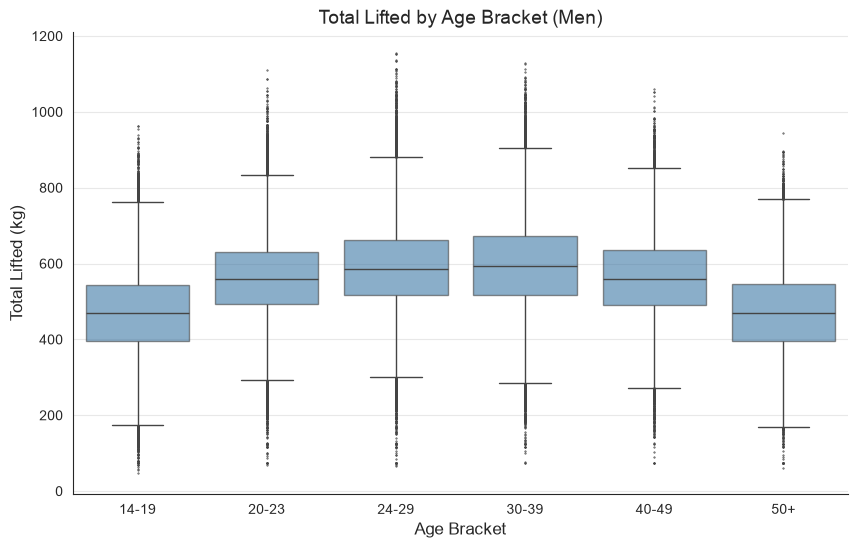

In [17]:
order = ['14-19', '20-23', '24-29', '30-39', '40-49', '50+']
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=sbd_df[sbd_df['sex'] == 'M'], x='age_bracket', y='total', order=order, color='#2c7bb6', fliersize=0.5, boxprops=dict(alpha=0.6))
ax.set_title("Total Lifted by Age Bracket (Men)")
ax.set_xlabel("Age Bracket")
ax.set_ylabel("Total Lifted (kg)")
ax.yaxis.grid(True, linestyle='-', color='lightgrey', alpha=0.5)
ax.set_axisbelow(True)
plt.show()


## 17. Total Lifted by Weight Class (IPF Men)


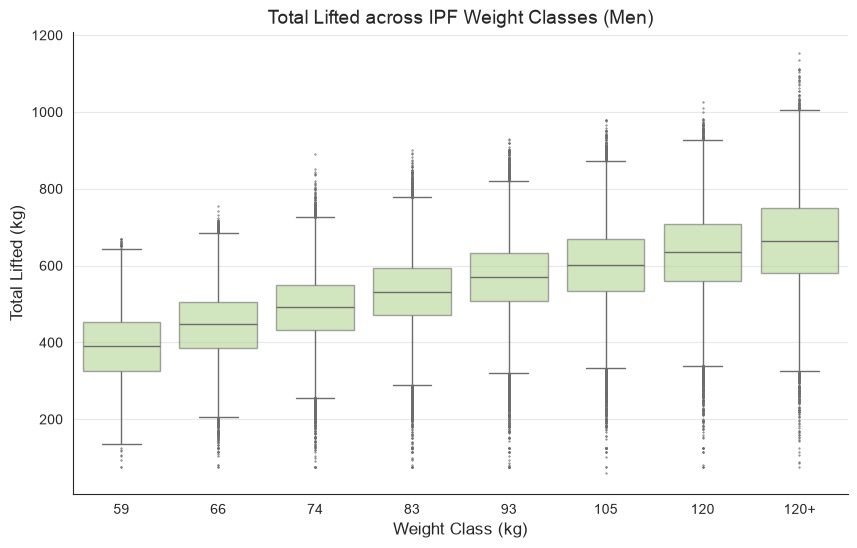

In [18]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=m_ipf, x='weight_class', y='total', color='#b2df8a', fliersize=0.5, boxprops=dict(alpha=0.6))
ax.set_title("Total Lifted across IPF Weight Classes (Men)")
ax.set_xlabel("Weight Class (kg)")
ax.set_ylabel("Total Lifted (kg)")
ax.yaxis.grid(True, linestyle='-', color='lightgrey', alpha=0.5)
ax.set_axisbelow(True)
plt.show()


## 18. DOTS by Weight Class (IPF Men)


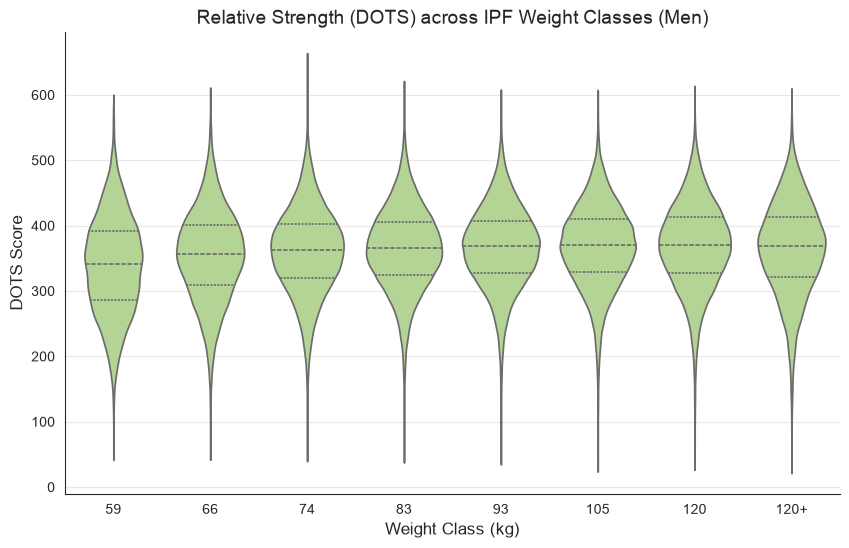

In [19]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.violinplot(data=m_ipf, x='weight_class', y='dots_score', color='#b2df8a', inner='quartile')
ax.set_title("Relative Strength (DOTS) across IPF Weight Classes (Men)")
ax.set_xlabel("Weight Class (kg)")
ax.set_ylabel("DOTS Score")
ax.yaxis.grid(True, linestyle='-', color='lightgrey', alpha=0.5)
ax.set_axisbelow(True)
plt.show()


## 19. Temporal Trends: Growth of the Sport


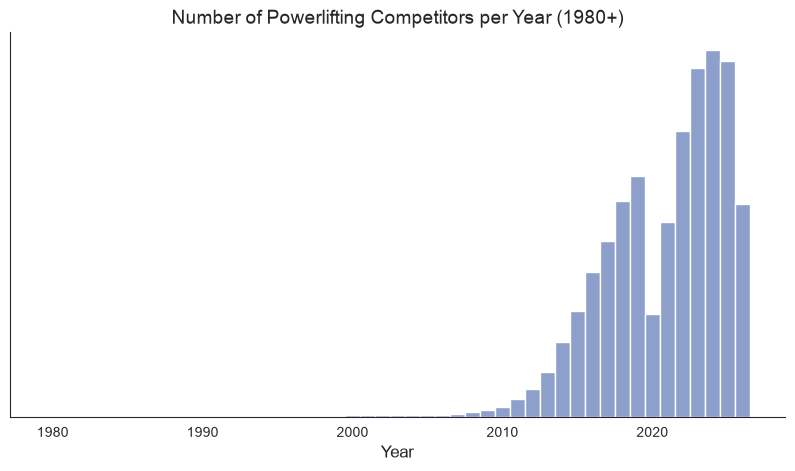

In [20]:
sbd_df['year'] = pd.to_datetime(sbd_df['date']).dt.year
yearly_counts = sbd_df[sbd_df['year'] >= 1980].groupby('year').size()
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(yearly_counts.index, yearly_counts.values, color='#8da0cb', width=1.0)
ax.set_title("Number of Powerlifting Competitors per Year (1980+)")
ax.set_xlabel("Year")
ax.set_yticks([])
plt.show()


## 20. Temporal Trends: Evolution of Strength


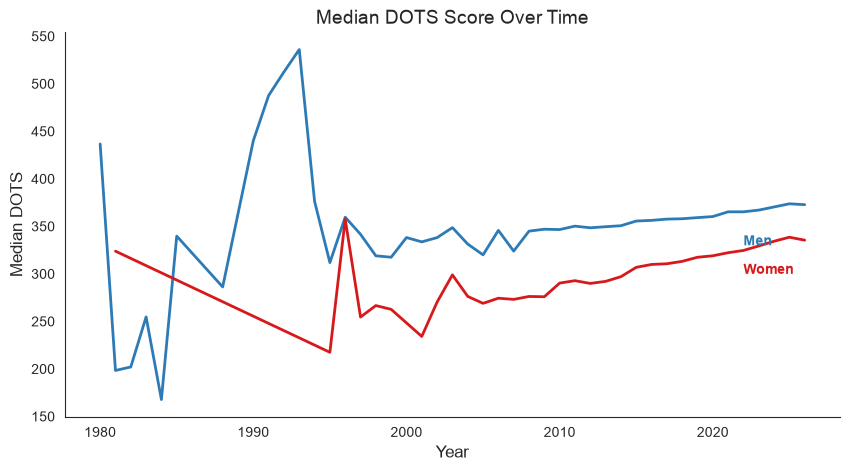

In [21]:
yearly_dots = sbd_df[sbd_df['year'] >= 1980].groupby(['year', 'sex'])['dots_score'].median().reset_index()
fig, ax = plt.subplots(figsize=(10, 5))
for sex, color in [('M', '#2c7bb6'), ('F', '#d7191c')]:
    subset = yearly_dots[yearly_dots['sex'] == sex]
    ax.plot(subset['year'], subset['dots_score'], color=color, linewidth=2)
ax.text(2022, 330, "Men", color='#2c7bb6', weight='bold')
ax.text(2022, 300, "Women", color='#d7191c', weight='bold')
ax.set_title("Median DOTS Score Over Time")
ax.set_xlabel("Year")
ax.set_ylabel("Median DOTS")
plt.show()


## 21. Temporal Trends: Average Age Over Time


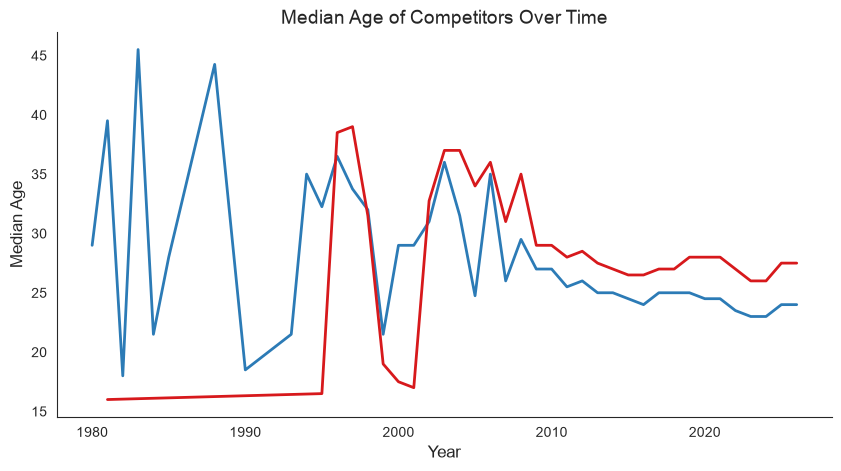

In [22]:
yearly_age = sbd_df[sbd_df['year'] >= 1980].groupby(['year', 'sex'])['age'].median().reset_index()
fig, ax = plt.subplots(figsize=(10, 5))
for sex, color in [('M', '#2c7bb6'), ('F', '#d7191c')]:
    subset = yearly_age[yearly_age['sex'] == sex]
    ax.plot(subset['year'], subset['age'], color=color, linewidth=2)
ax.set_title("Median Age of Competitors Over Time")
ax.set_xlabel("Year")
ax.set_ylabel("Median Age")
plt.show()


## 22. Lifter Retention (Meets per Lifter)


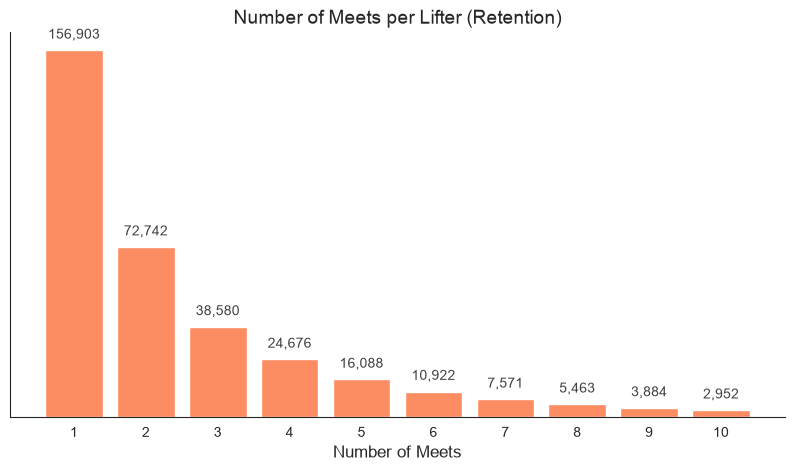

In [23]:
lifter_counts = sbd_df['lifter_id'].value_counts()
counts_dist = lifter_counts.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 5))
# Only show up to 10 meets for clarity
ax.bar(counts_dist.index[:10], counts_dist.values[:10], color='#fc8d62')
for i in range(1, 11):
    if i in counts_dist.index:
        ax.text(i, counts_dist[i] + 5000, f"{counts_dist[i]:,}", ha='center', color='#404040', fontsize=10)
ax.set_title("Number of Meets per Lifter (Retention)")
ax.set_xlabel("Number of Meets")
ax.set_xticks(range(1, 11))
ax.set_yticks([])
plt.show()


## 23. Lifter Progression (Spaghetti Plot)


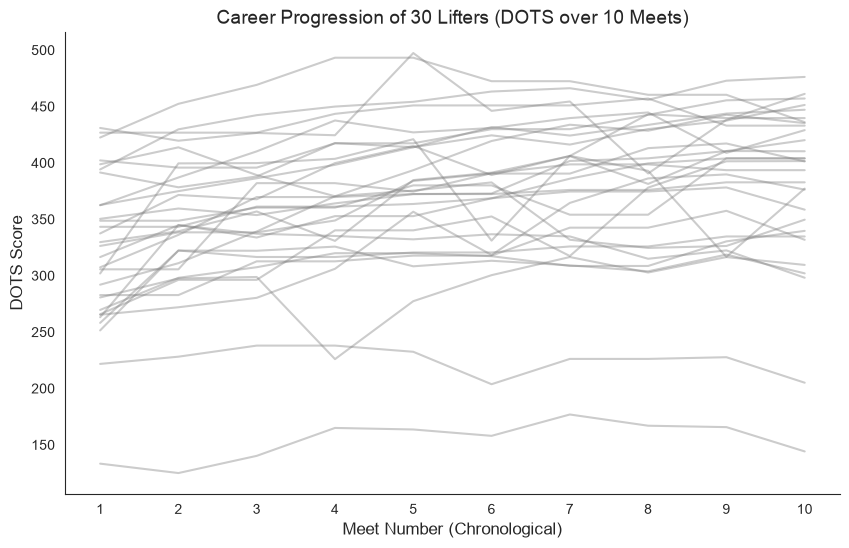

In [24]:
# Select 30 random lifters who have exactly 10 meets
long_careers = lifter_counts[lifter_counts == 10].index
np.random.seed(42)
sample_lifters = np.random.choice(long_careers, 30, replace=False)
progression_df = sbd_df[sbd_df['lifter_id'].isin(sample_lifters)].copy()
progression_df = progression_df.sort_values(['lifter_id', 'date'])
progression_df['meet_number'] = progression_df.groupby('lifter_id').cumcount() + 1

fig, ax = plt.subplots(figsize=(10, 6))
for lifter in sample_lifters:
    subset = progression_df[progression_df['lifter_id'] == lifter]
    ax.plot(subset['meet_number'], subset['dots_score'], alpha=0.4, color='grey', linewidth=1.5)
ax.set_title("Career Progression of 30 Lifters (DOTS over 10 Meets)")
ax.set_xlabel("Meet Number (Chronological)")
ax.set_ylabel("DOTS Score")
ax.set_xticks(range(1, 11))
plt.show()


## 24. Biomechanics: Lift Proportions by Weight Class (IPF Men)


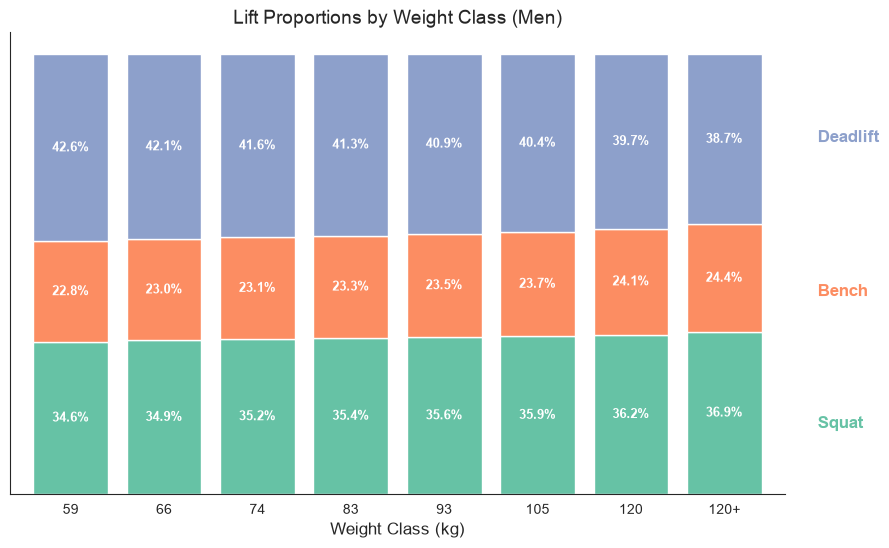

In [25]:
m_ipf_sbd = sbd_df[(sbd_df['sex'] == 'M') & (sbd_df['tested_status'] == True) & (sbd_df['weight_class'].isin(ipf_classes_m))].copy()
m_ipf_sbd['weight_class'] = pd.Categorical(m_ipf_sbd['weight_class'], categories=ipf_classes_m, ordered=True)

props = m_ipf_sbd.groupby('weight_class')[['squat', 'bench', 'deadlift']].mean()
props_pct = props.div(props.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(10, 6))
props_pct.plot(kind='bar', stacked=True, ax=ax, color=['#66c2a5', '#fc8d62', '#8da0cb'], width=0.8)

for c in ax.containers:
    labels = [f"{v.get_height():.1f}%" for v in c]
    ax.bar_label(c, labels=labels, label_type='center', color='white', weight='bold', fontsize=9)

ax.set_title("Lift Proportions by Weight Class (Men)")
ax.set_xlabel("Weight Class (kg)")
ax.set_yticks([])
ax.legend().remove()
ax.text(8.0, 80, "Deadlift", color='#8da0cb', weight='bold', fontsize=12)
ax.text(8.0, 45, "Bench", color='#fc8d62', weight='bold', fontsize=12)
ax.text(8.0, 15, "Squat", color='#66c2a5', weight='bold', fontsize=12)
plt.xticks(rotation=0)
plt.show()


## 25. Wilks vs DOTS (Divergence at Extreme Bodyweights)


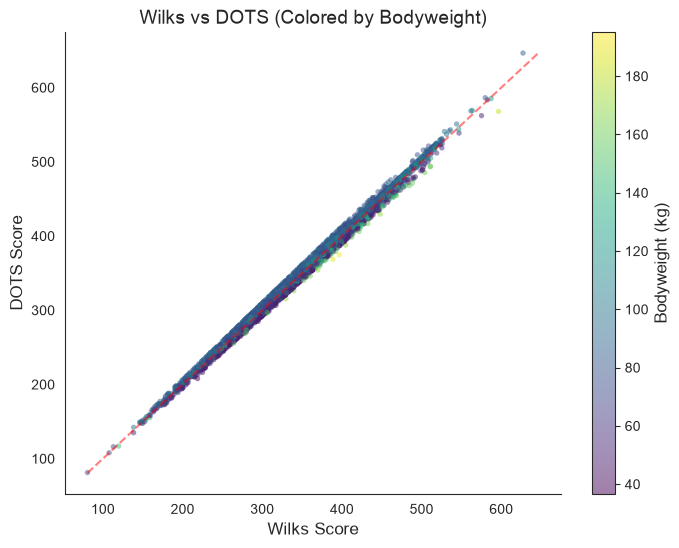

In [26]:
sample_scores = sbd_df.dropna(subset=['wilks_score', 'dots_score']).sample(5000, random_state=42)
fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(sample_scores['wilks_score'], sample_scores['dots_score'], c=sample_scores['bodyweight'], cmap='viridis', alpha=0.5, s=15, edgecolors='none')
plt.colorbar(sc, label='Bodyweight (kg)')
min_v = min(sample_scores['wilks_score'].min(), sample_scores['dots_score'].min())
max_v = max(sample_scores['wilks_score'].max(), sample_scores['dots_score'].max())
ax.plot([min_v, max_v], [min_v, max_v], 'r--', alpha=0.5)
ax.set_title("Wilks vs DOTS (Colored by Bodyweight)")
ax.set_xlabel("Wilks Score")
ax.set_ylabel("DOTS Score")
plt.show()


## 26. The Case for Normalization: Raw kg vs Normalized Score


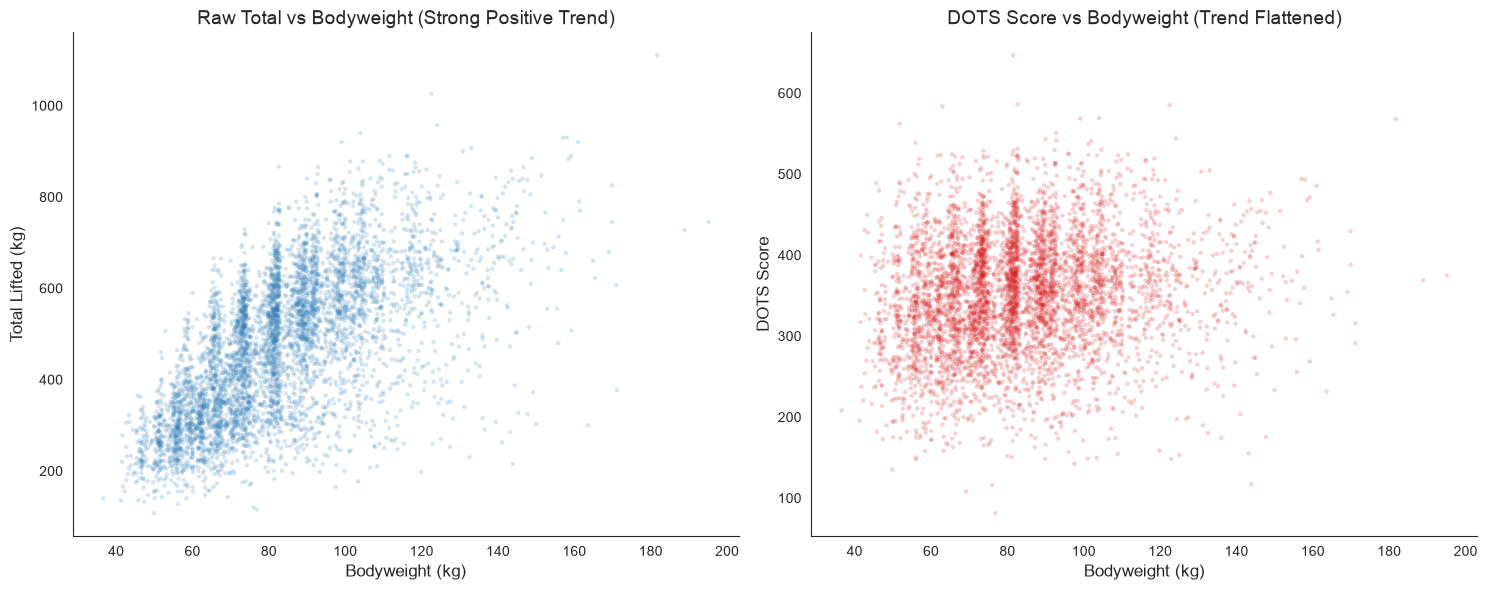

In [27]:
sample_norm = sbd_df.sample(5000, random_state=42)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
ax1.scatter(sample_norm['bodyweight'], sample_norm['total'], alpha=0.2, s=10, color='#2c7bb6', edgecolors='none')
ax1.set_title("Raw Total vs Bodyweight (Strong Positive Trend)")
ax1.set_xlabel("Bodyweight (kg)")
ax1.set_ylabel("Total Lifted (kg)")

ax2.scatter(sample_norm['bodyweight'], sample_norm['dots_score'], alpha=0.2, s=10, color='#d7191c', edgecolors='none')
ax2.set_title("DOTS Score vs Bodyweight (Trend Flattened)")
ax2.set_xlabel("Bodyweight (kg)")
ax2.set_ylabel("DOTS Score")
plt.tight_layout()
plt.show()


## 27. Women's Participation Growth Over Time


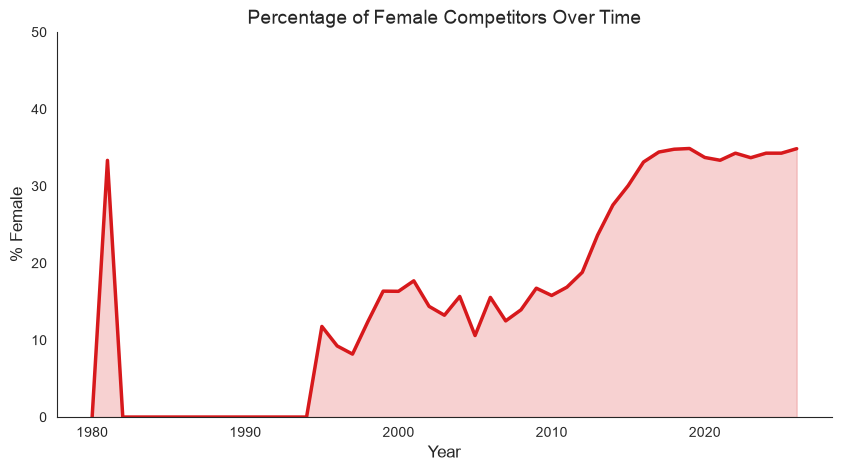

In [28]:
yearly_gender = sbd_df[sbd_df['year'] >= 1980].groupby(['year', 'sex']).size().unstack(fill_value=0)
yearly_gender['Total'] = yearly_gender['M'] + yearly_gender['F']
yearly_gender['F_Pct'] = (yearly_gender['F'] / yearly_gender['Total']) * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(yearly_gender.index, yearly_gender['F_Pct'], color='#d7191c', linewidth=2.5)
ax.fill_between(yearly_gender.index, yearly_gender['F_Pct'], color='#d7191c', alpha=0.2)
ax.set_title("Percentage of Female Competitors Over Time")
ax.set_xlabel("Year")
ax.set_ylabel("% Female")
ax.set_ylim(0, 50)
plt.show()


## 28. SBD Ratio Distribution by Sex


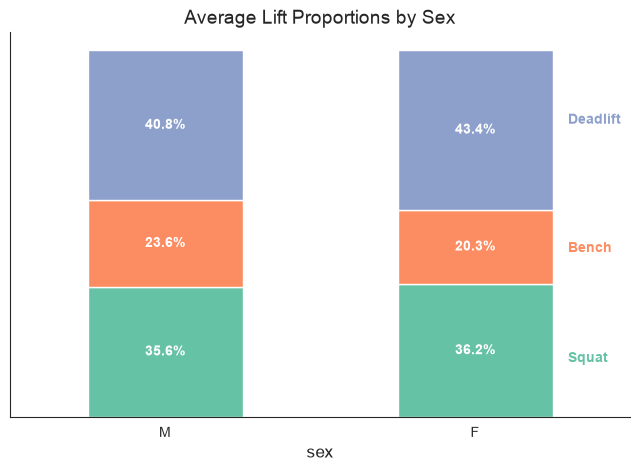

In [29]:
props_sex = sbd_df.groupby('sex')[['squat', 'bench', 'deadlift']].mean()
props_sex_pct = props_sex.div(props_sex.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(8, 5))
props_sex_pct.loc[['M', 'F']].plot(kind='bar', stacked=True, ax=ax, color=['#66c2a5', '#fc8d62', '#8da0cb'], width=0.5)

for c in ax.containers:
    labels = [f"{v.get_height():.1f}%" for v in c]
    ax.bar_label(c, labels=labels, label_type='center', color='white', weight='bold')

ax.set_title("Average Lift Proportions by Sex")
ax.set_yticks([])
ax.legend().remove()
ax.text(1.3, 80, "Deadlift", color='#8da0cb', weight='bold')
ax.text(1.3, 45, "Bench", color='#fc8d62', weight='bold')
ax.text(1.3, 15, "Squat", color='#66c2a5', weight='bold')
plt.xticks(rotation=0)
plt.show()


## 29. Coefficient of Variation (Relative Variance)


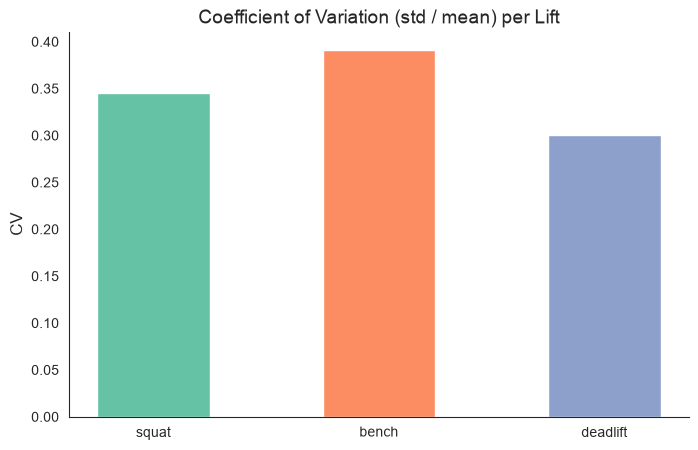

In [30]:
cv = sbd_df[['squat', 'bench', 'deadlift']].std() / sbd_df[['squat', 'bench', 'deadlift']].mean()
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(cv.index, cv.values, color=['#66c2a5', '#fc8d62', '#8da0cb'], width=0.5)
ax.set_title("Coefficient of Variation (std / mean) per Lift")
ax.set_ylabel("CV")
plt.show()


## 30. Tested vs Untested Totals (93kg Men)


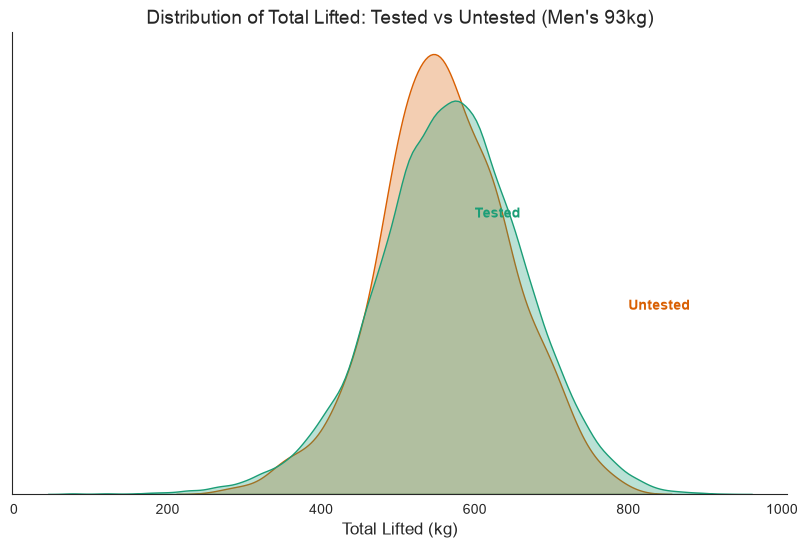

In [31]:
men_93 = sbd_df[(sbd_df['sex'] == 'M') & (sbd_df['weight_class'] == '93')]
fig, ax = plt.subplots(figsize=(10, 6))
sns.kdeplot(data=men_93[men_93['tested_status'] == False]['total'], fill=True, alpha=0.3, color='#d95f02', ax=ax)
sns.kdeplot(data=men_93[men_93['tested_status'] == True]['total'], fill=True, alpha=0.3, color='#1b9e77', ax=ax)
ax.text(800, 0.002, 'Untested', color='#d95f02', weight='bold')
ax.text(600, 0.003, 'Tested', color='#1b9e77', weight='bold')
ax.set_title("Distribution of Total Lifted: Tested vs Untested (Men's 93kg)")
ax.set_xlabel("Total Lifted (kg)")
ax.set_yticks([])
ax.set_ylabel("")
plt.show()


## 31. Rate of Progress by Training Age


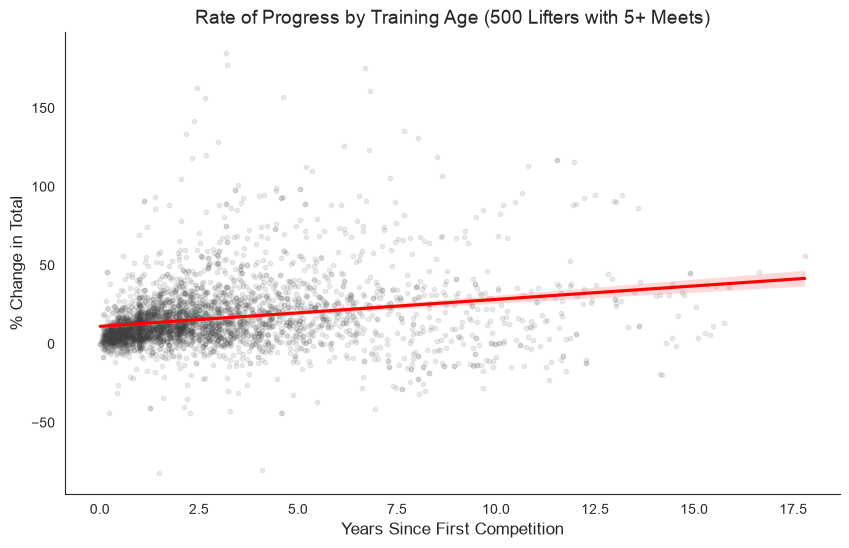

In [32]:
# Get lifters with 5+ meets
lifter_meet_counts = sbd_df['lifter_id'].value_counts()
multi_lifters = lifter_meet_counts[lifter_meet_counts >= 5].index
np.random.seed(42)
sample_multi = np.random.choice(multi_lifters, 500, replace=False)

prog_df = sbd_df[sbd_df['lifter_id'].isin(sample_multi)].copy()
prog_df['date'] = pd.to_datetime(prog_df['date'])
prog_df = prog_df.sort_values(['lifter_id', 'date'])

# Calculate first meet stats per lifter
first_meets = prog_df.groupby('lifter_id').first()
prog_df = prog_df.merge(first_meets[['date', 'total']], on='lifter_id', suffixes=('', '_first'))

prog_df['years_since_first'] = (prog_df['date'] - prog_df['date_first']).dt.days / 365.25
prog_df['pct_change_total'] = ((prog_df['total'] - prog_df['total_first']) / prog_df['total_first']) * 100

# Filter out the first meet itself (0 change, 0 years)
prog_df = prog_df[prog_df['years_since_first'] > 0]

fig, ax = plt.subplots(figsize=(10, 6))
sns.regplot(data=prog_df, x='years_since_first', y='pct_change_total', scatter_kws={'alpha':0.1, 's':10, 'color':'#404040'}, line_kws={'color':'red'})
ax.set_title("Rate of Progress by Training Age (500 Lifters with 5+ Meets)")
ax.set_xlabel("Years Since First Competition")
ax.set_ylabel("% Change in Total")
plt.show()
